In [1]:
import numpy as np


def evaluar(poblacion, funcion):
    """Evalúa todas las soluciones de una población."""
    return np.array(
        [funcion(x) for x in poblacion],
        dtype=float
    )

def pso(
    funcion,
    limites,
    tamano=30,
    iteraciones=100,
    w=0.7,
    c1=1.5,
    c2=1.5,
    semilla=42
):
    rng = np.random.default_rng(semilla)

    limites = np.asarray(limites, dtype=float)
    inferior = limites[:, 0]
    superior = limites[:, 1]
    dimension = len(inferior)

    # 1. Crear partículas en posiciones aleatorias.
    posiciones = rng.uniform(
        inferior, superior, (tamano, dimension)
    )

    # 2. Darles velocidades iniciales aleatorias.
    velocidades = rng.uniform(
        -0.1 * (superior - inferior),
        0.1 * (superior - inferior),
        (tamano, dimension)
    )

    # 3. Inicializar memorias personales.
    mejores_personales = posiciones.copy()
    errores_personales = evaluar(posiciones, funcion)

    # 4. Identificar la mejor solución global.
    indice = np.argmin(errores_personales)

    mejor_global = mejores_personales[indice].copy()
    error_global = errores_personales[indice]

    historial = [error_global]
    trayectorias = [posiciones.copy()]

    # 5. Ciclo de optimización.
    for _ in range(1, iteraciones + 1):

        # Números aleatorios independientes por partícula
        # y por dimensión.
        r1 = rng.random((tamano, dimension))
        r2 = rng.random((tamano, dimension))

        # 6. Actualizar velocidades.
        velocidades = (
            w * velocidades
            + c1 * r1 * (mejores_personales - posiciones)
            + c2 * r2 * (mejor_global - posiciones)
        )

        # Limitar la magnitud de las velocidades.
        velocidad_maxima = 0.2 * (superior - inferior)
        velocidades = np.clip(
            velocidades,
            -velocidad_maxima,
            velocidad_maxima
        )

        # 7. Actualizar posiciones y respetar límites.
        posiciones = np.clip(
            posiciones + velocidades,
            inferior,
            superior
        )
        trayectorias.append(posiciones.copy())

        # 8. Evaluar las nuevas posiciones.
        errores = evaluar(posiciones, funcion)

        # 9. Actualizar mejores posiciones personales.
        mejoraron = errores < errores_personales

        mejores_personales[mejoraron] = posiciones[mejoraron]
        errores_personales[mejoraron] = errores[mejoraron]

        # 10. Actualizar el mejor global.
        indice = np.argmin(errores_personales)

        if errores_personales[indice] < error_global:
            error_global = errores_personales[indice]
            mejor_global = mejores_personales[indice].copy()

        historial.append(error_global)


    return {
        "posicion": mejor_global,
        "error": error_global,
        "historial": np.array(historial),
        "trayectorias": trayectorias
    }

In [2]:
f = lambda x: \
    (1.5 - x[0] +x[0]*x[1])**2 + (2.25 - x[0] + x[0]*x[1]**2)**2 + (2.625 - x[0] + x[0]*x[1]**3)**2

    #np.sum(x**2)
    #10*len(x) + np.sum(x**2 - 10*np.cos(2*math.pi*x))
    #-20*np.exp(-0.2*np.sqrt(0.5*(x[0]**2+x[1]**2)))-np.exp(0.5*(np.cos(2*np.pi*x[0])+np.cos(2*np.pi*x[1])))+ np.e + 20
    
dimensiones = 2
limites = [(-5.12,5.12)] * dimensiones
result =  pso(
    funcion=f,
    limites=limites,
    iteraciones=8,
    tamano=20,
    semilla=42
)

print("PSO:", result["posicion"])

PSO: [2.76900637 0.44605161]


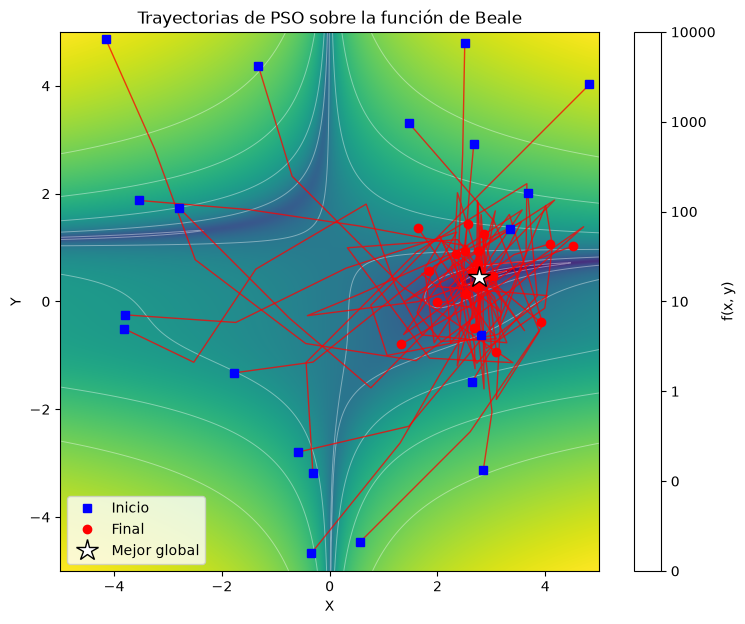

In [36]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


# the "peaks" function
def peaks(x,y):
  # expand to a 2D mesh
  x,y = np.meshgrid(x,y)
  
  z = \
    (1.5 - x +x*y)**2 + (2.25 - x +x*y**2)**2 + (2.625 - x +x*y**3)**2

      #x**2 + y**2
      #20 + (x**2 - 10*np.cos(2*np.pi*x)) + (y**2 - 10*np.cos(2*np.pi*y))
      #-20*np.exp(-0.2*np.sqrt(0.5*(x**2+y**2)))-np.exp(0.5*(np.cos(2*np.pi*x)+np.cos(2*np.pi*y)))+ np.e + 20
       
        
  return z

# Crear el paisaje
x = np.linspace(-5, 5, 1000)
y = np.linspace(-5,5, 1000)

X, Y = np.meshgrid(x, y)

Z = peaks(x, y)

trayectorias = np.array(result["trayectorias"])

plt.figure(figsize=(9, 7))

# 1. Graficar con escala logarítmica
plt.imshow(
    Z,
    extent=[x[0], x[-1], y[0], y[-1]],
    origin="lower",
    cmap="viridis",
    norm=LogNorm(vmin=0.01, vmax=Z.max())
)

# 2. Agregar curvas de nivel
plt.contour(
    X, Y, Z,
    levels=[0.01, 0.1, 1, 10, 100, 1000, 10000],
    colors="white",
    alpha=0.4,
    linewidths=0.7
)

# 3. Graficar trayectorias
for i in range(trayectorias.shape[1]):
    plt.plot(
        trayectorias[:, i, 0],
        trayectorias[:, i, 1],
        color="red",
        alpha=0.75,
        linewidth=1
    )

# 4. Posiciones iniciales
plt.plot(
    trayectorias[0, :, 0],
    trayectorias[0, :, 1],
    "bs",
    label="Inicio"
)

# 5. Posiciones finales
plt.plot(
    trayectorias[-1, :, 0],
    trayectorias[-1, :, 1],
    "ro",
    label="Final"
)

# 6. Mejor posición global
plt.plot(
    result["posicion"][0],
    result["posicion"][1],
    marker="*",
    color="white",
    markeredgecolor="black",
    markersize=16,
    linestyle="None",
    label="Mejor global"
)

# 7. Mantener los límites de la gráfica
plt.xlim(x[0], x[-1])
plt.ylim(y[0], y[-1])

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Trayectorias de PSO sobre la función de Beale")

plt.legend()
plt.colorbar(label="f(x, y)")
plt.show()
